# Skin friction under pressure gradients

Run the cells below to generate the case report from the paper's saved results. The report shows the system's completed analysis cards and result figures. Report generation uses local files.

The final section runs a new analysis from the case input data and configuration when `RUN_NEW_ANALYSIS` is enabled.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/cases').is_dir() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))

from IPython.display import display, HTML, Image
from ai_buckingham import build_agent_graph
from ai_buckingham.artifacts import new_run_id
from ai_buckingham.cli import run_analysis
from ai_buckingham.notebook import published_run
from ai_buckingham.reports import render_report, export_report

In [2]:
CASE_ID = 'pressure_gradient'
RUN_DIR = published_run(CASE_ID, ROOT)

## Executable workflow

LangGraph draws this diagram using its native Mermaid renderer. Rerunning this cell requires Internet access to the rendering service.

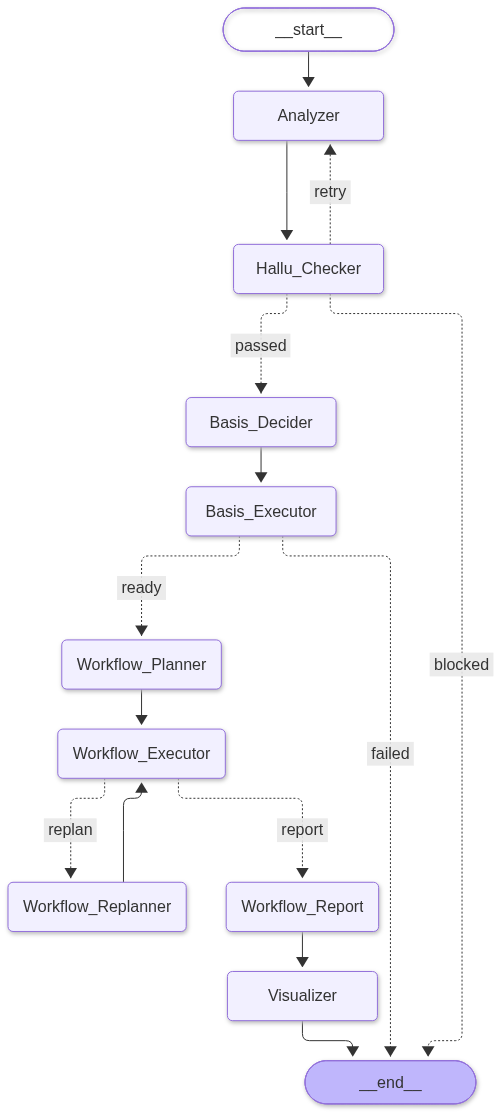

In [3]:
agent_graph = build_agent_graph()
display(Image(agent_graph.get_graph().draw_mermaid_png()))

## Case results


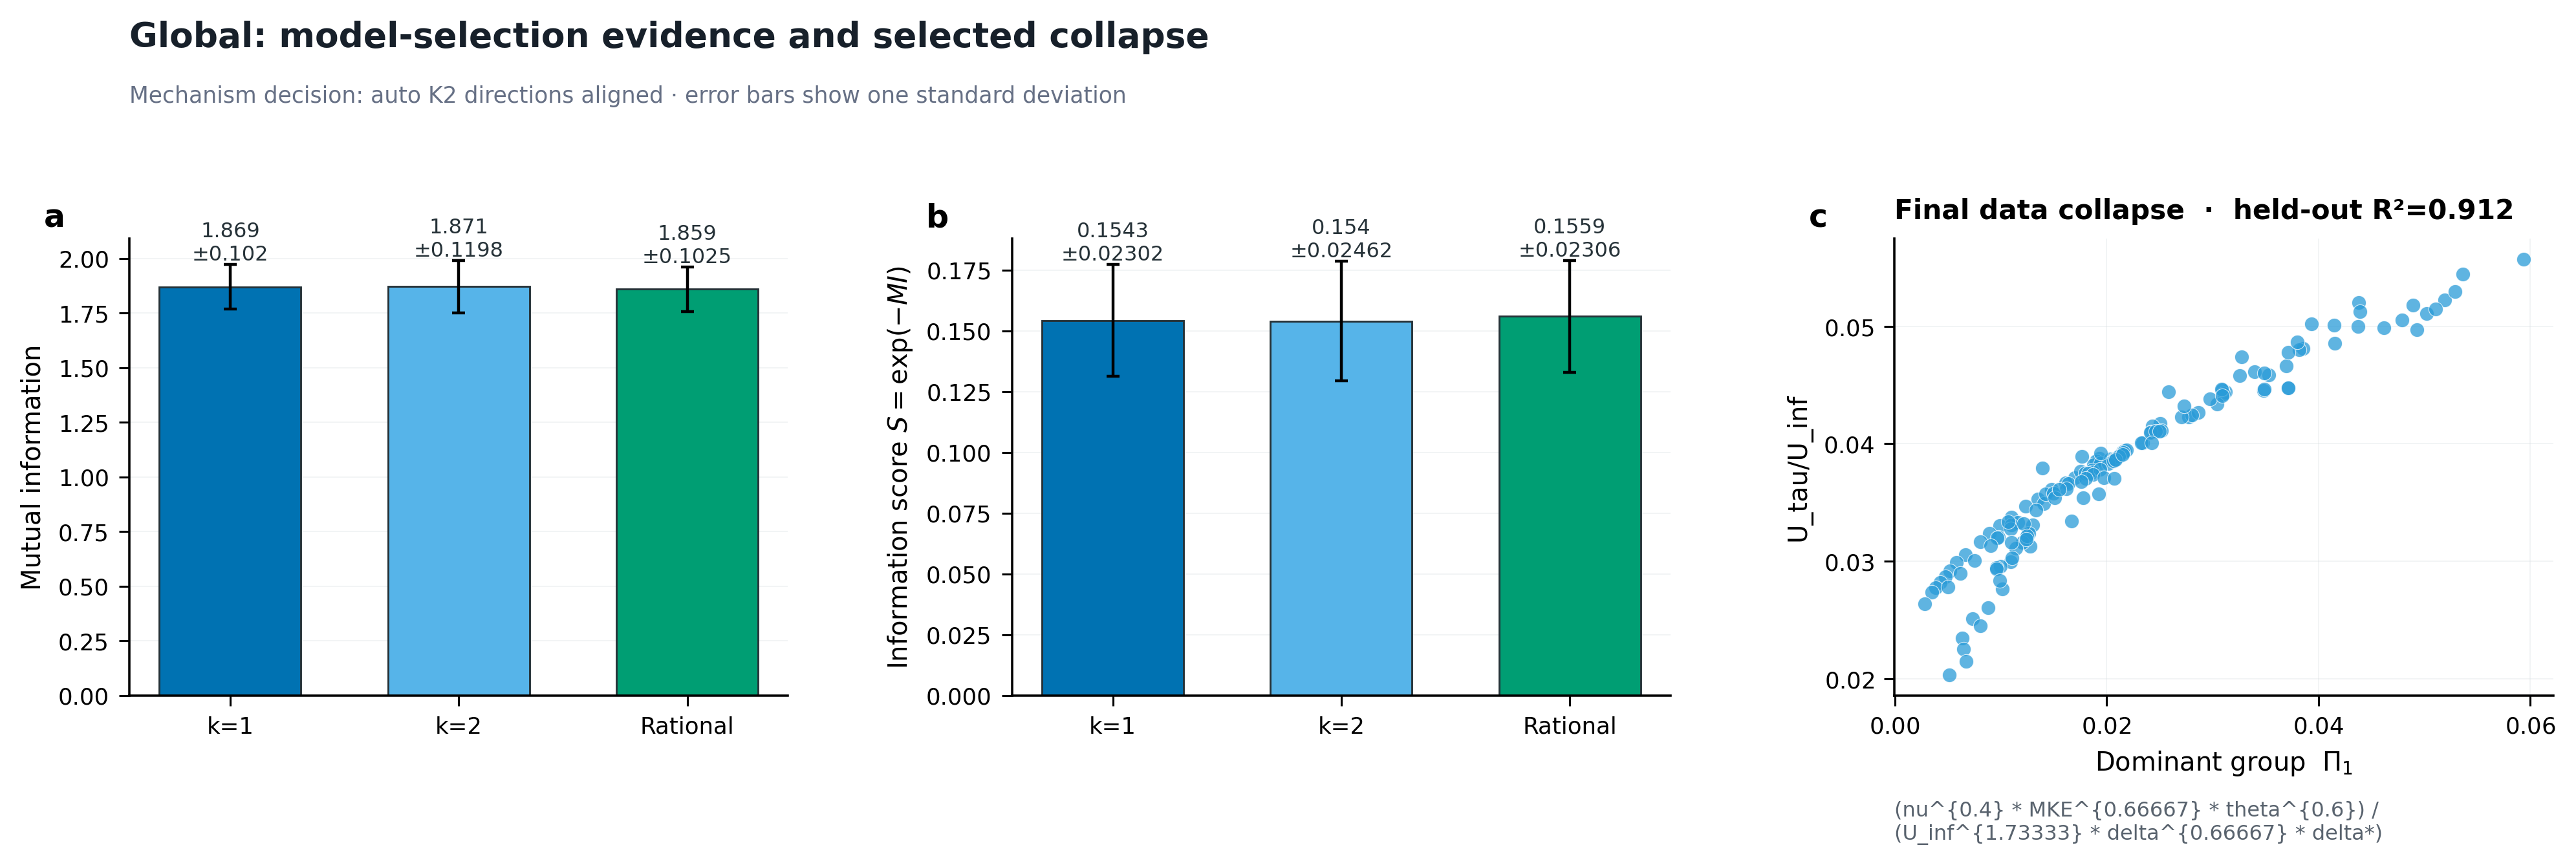

In [4]:
RESULT_HTML = render_report(RUN_DIR)
display(HTML(RESULT_HTML))

## Save the HTML report

Set `SAVE_HTML = True` to write a standalone copy under `generated/reports/`. Open the resulting `result.html` in a browser.

In [5]:
SAVE_HTML = False
if SAVE_HTML:
    report_path = export_report(RUN_DIR, ROOT / 'generated' / 'reports' / CASE_ID / 'result.html')

## Run a new analysis

The input data and analysis settings are in [the pressure_gradient configuration](../../configs/cases/pressure_gradient.json). Configure the model and embedding credentials described in [the README](../../README.md#run-locally), then set `RUN_NEW_ANALYSIS = True`. This runs the full workflow and can take substantial time. The new cards and files are saved in a separate `generated/cases/` run directory.

The command-line equivalent from the repository root is `ai-buckingham pressure_gradient`.

In [6]:
RUN_NEW_ANALYSIS = False
if RUN_NEW_ANALYSIS:
    NEW_RUN_DIR = ROOT / 'generated' / 'cases' / CASE_ID / new_run_id()
    state = run_analysis(CASE_ID, output_dir=NEW_RUN_DIR, agent_graph=agent_graph, display_cards=False)
    display(HTML(render_report(NEW_RUN_DIR)))